In [1]:
# LOADING THE LIBRARIES NEEDED

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load diabetes dataset

df = pd.read_csv("diabetes.csv")

print(df.head())

print("\nShape of dataset:")
print(df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Shape of dataset:
(768, 9)


In [4]:
# datatype check

print("\nData types:")
print(df.dtypes)

# missing values check

print("\nMissing values:")
print(df.isnull().sum())


Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [6]:
# X contains input attributes

X = df.drop("Outcome", axis=1)

# y contains target

y = df["Outcome"]

print("Input attributes:")
print(X.columns)

print("\nTarget:")
print(y.name)

Input attributes:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')

Target:
Outcome


In [7]:
# Columns where 0 is considered an invalid/missing value

zero_missing_cols = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace 0 with NaN

X[zero_missing_cols] = X[zero_missing_cols].replace(0, np.nan)

print("\nMissing values after replacing 0:")
print(X.isnull().sum())


Missing values after replacing 0:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [8]:
# Fill missing values with median

for col in zero_missing_cols:
    X[col] = X[col].fillna(X[col].median())

print("\nMissing values after handling:")
print(X.isnull().sum())


Missing values after handling:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [10]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nDataset shape:")
print(df.shape)

Training records: 614
Testing records: 154

Dataset shape:
(768, 9)


In [11]:
# CART MODEL
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train the model

cart_model.fit(X_train, y_train)

# Predict classes

cart_pred = cart_model.predict(X_test)

In [12]:
# CART evaluation

cart_accuracy = accuracy_score(
    y_test,
    cart_pred
)

cart_precision = precision_score(
    y_test,
    cart_pred,
    average="weighted",
    zero_division=0
)

cart_recall = recall_score(
    y_test,
    cart_pred,
    average="weighted",
    zero_division=0
)

cart_f1 = f1_score(
    y_test,
    cart_pred,
    average="weighted",
    zero_division=0
)

print("CART Results")

print("Accuracy :", cart_accuracy)
print("Precision:", cart_precision)
print("Recall   :", cart_recall)
print("F1 Score :", cart_f1)

CART Results
Accuracy : 0.8116883116883117
Precision: 0.809748789189109
Recall   : 0.8116883116883117
F1 Score : 0.8103896103896103


In [13]:
# ID3 MODEL

id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

# Train the model

id3_model.fit(X_train, y_train)

# Make predictions

id3_pred = id3_model.predict(X_test)

In [14]:
# ID3 evaluation

id3_accuracy = accuracy_score(
    y_test,
    id3_pred
)

id3_precision = precision_score(
    y_test,
    id3_pred,
    average="weighted",
    zero_division=0
)

id3_recall = recall_score(
    y_test,
    id3_pred,
    average="weighted",
    zero_division=0
)

id3_f1 = f1_score(
    y_test,
    id3_pred,
    average="weighted",
    zero_division=0
)

print("ID3 Results")

print("Accuracy :", id3_accuracy)
print("Precision:", id3_precision)
print("Recall   :", id3_recall)
print("F1 Score :", id3_f1)

ID3 Results
Accuracy : 0.8441558441558441
Precision: 0.8457129605088789
Recall   : 0.8441558441558441
F1 Score : 0.8447855175127902


In [16]:
from chefboost import Chefboost as chef

In [21]:
c45_data = X.copy()

# Add target column
c45_data["Decision"] = y

# Convert target into string/object
c45_data["Decision"] = c45_data["Decision"].map({
    0: "No",
    1: "Yes"
}).astype(object)

print(c45_data.head())

print("\nData types:")
print(c45_data.dtypes)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age Decision  
0                     0.627   50      Yes  
1                     0.351   31       No  
2                     0.672   32      Yes  
3                     0.167   21       No  
4                     2.288   33      Yes  

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure               float64
SkinThickness                 int64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
De

In [22]:
# Split C4.5 data

c45_train, c45_test = train_test_split(
    c45_data,
    test_size=0.20,
    random_state=42,
    stratify=c45_data["Decision"]
)

print("C4.5 Training records:", len(c45_train))
print("C4.5 Testing records:", len(c45_test))

C4.5 Training records: 614
C4.5 Testing records: 154


In [23]:
print("\nC4.5 target datatype:")
print(c45_train["Decision"].dtype)

print("\nC4.5 target values:")
print(c45_train["Decision"].unique())

print("\nTarget distribution:")
print(c45_train["Decision"].value_counts())


C4.5 target datatype:
object

C4.5 target values:
['No' 'Yes']

Target distribution:
Decision
No     400
Yes    214
Name: count, dtype: int64


In [24]:
# C4.5 configuration

config = {
    "algorithm": "C4.5"
}

# Train C4.5

c45_model = chef.fit(
    c45_train,
    config=config,
    target_label="Decision"
)

26-09-02 10:07:23 - C4.5 tree is going to be built...
26-09-02 10:07:31 - -------------------------
26-09-02 10:07:31 - finished in 7.657132863998413 seconds
26-09-02 10:07:31 - -------------------------
26-09-02 10:07:31 - Evaluate train set
26-09-02 10:07:31 - -------------------------
26-09-02 10:07:31 - Accuracy: 87.78501628664495% on 614 instances
26-09-02 10:07:31 - Labels: ['No' 'Yes']
26-09-02 10:07:31 - Confusion matrix: [[353, 28], [47, 186]]
26-09-02 10:07:31 - Precision: 92.6509%, Recall: 88.25%, F1: 90.3969%


In [25]:
# Make C4.5 predictions

c45_pred = []

for _, row in c45_test.drop("Decision", axis=1).iterrows():

    prediction = chef.predict(
        c45_model,
        param=row.tolist()
    )

    c45_pred.append(prediction)

c45_pred = np.array(c45_pred)

print("C4.5 Predictions:")
print(c45_pred[:20])

C4.5 Predictions:
['No' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No'
 'No' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No']


In [26]:
# Actual test values

c45_actual = c45_test["Decision"].values

print("Actual values:")
print(c45_actual[:20])

Actual values:
['No' 'No' 'No' 'Yes' 'No' 'No' 'Yes' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No'
 'Yes' 'Yes' 'No' 'No' 'No' 'No']


In [27]:
# C4.5 evaluation

c45_accuracy = accuracy_score(
    c45_actual,
    c45_pred
)

c45_precision = precision_score(
    c45_actual,
    c45_pred,
    average="weighted",
    zero_division=0
)

c45_recall = recall_score(
    c45_actual,
    c45_pred,
    average="weighted",
    zero_division=0
)

c45_f1 = f1_score(
    c45_actual,
    c45_pred,
    average="weighted",
    zero_division=0
)

print("C4.5 Results")

print("Accuracy :", c45_accuracy)
print("Precision:", c45_precision)
print("Recall   :", c45_recall)
print("F1 Score :", c45_f1)

C4.5 Results
Accuracy : 0.8571428571428571
Precision: 0.869047619047619
Recall   : 0.8571428571428571
F1 Score : 0.8594367274117498


In [28]:
# COMPARISON OF ALL THREE ALGORITHMS

comparison = pd.DataFrame({
    "Algorithm": ["CART", "ID3", "C4.5"],
    "Accuracy": [cart_accuracy, id3_accuracy, c45_accuracy],
    "Precision": [cart_precision, id3_precision, c45_precision],
    "Recall": [cart_recall, id3_recall, c45_recall],
    "F1 Score": [cart_f1, id3_f1, c45_f1]
})

print("\nComparison of CART, ID3 and C4.5")
print(comparison)


Comparison of CART, ID3 and C4.5
  Algorithm  Accuracy  Precision    Recall  F1 Score
0      CART  0.811688   0.809749  0.811688  0.810390
1       ID3  0.844156   0.845713  0.844156  0.844786
2      C4.5  0.857143   0.869048  0.857143  0.859437


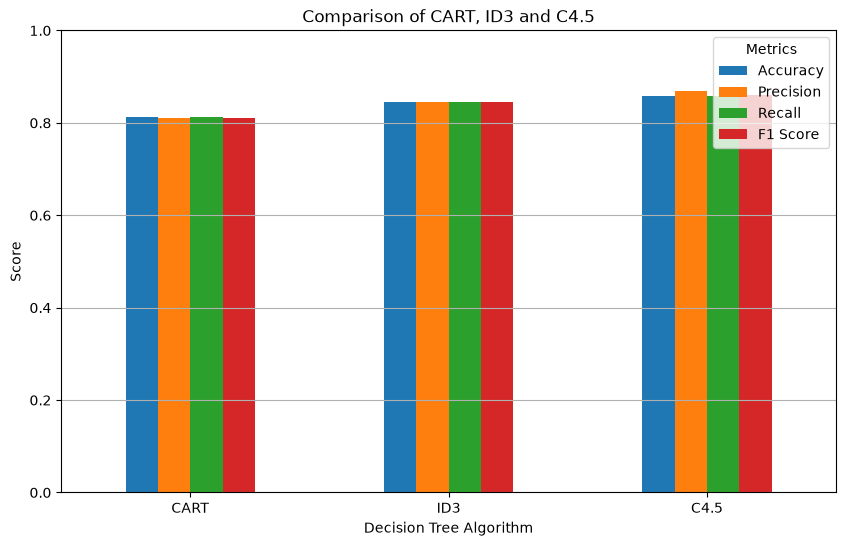

In [29]:
comparison.set_index("Algorithm").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of CART, ID3 and C4.5")
plt.xlabel("Decision Tree Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y")
plt.show()